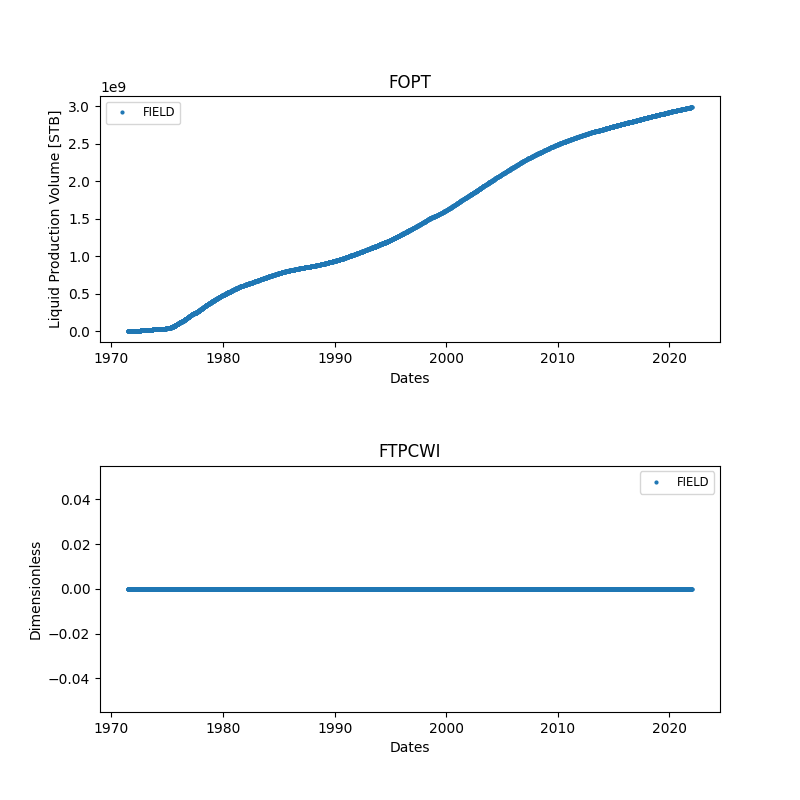

In [1]:
from IORlib.ECL import RFT_file, UNRST_file, UNSMRY_file
from pathlib import Path

#import matplotlib.pyplot as pl
%matplotlib widget

home = Path.home()
cop = Path('/home/shared/owner/CoP_files')
root = cop/'input/IORSIM_BASECASE_TRACER/IORSIM_BASECASE_INPUT'
unrst = UNRST_file(root)
rft = RFT_file(root)
smry = UNSMRY_file(root)
smry.welldata()
#smry.keys
smry.plot(keys=('FOPT', 'FTPCWI',))

In [ ]:
import enum
from operator import attrgetter
import matplotlib.pyplot as pl
from IORlib.ECL import UNRST_file
from pathlib import Path

%matplotlib widget

home = Path.home()
cop = Path('/home/shared/owner/CoP_files')
root = cop/'input/IORSIM_BASECASE_TRACER/IORSIM_BASECASE_INPUT'
unrst = UNRST_file(root)
vars = ('SWAT', 'TBLKWR', 'TBLKWI')
data = unrst.icellarray(*vars, step=100)
pl.close('all')
for D in data:
    fig, ax = pl.subplots(ncols=len(vars), figsize=(10, 3.5))
    fig.suptitle(D.date)
    for i,var in enumerate(vars):
        im = ax[i].imshow(attrgetter(var.lower())(D)[:,:,10].T)
        ax[i].set_title(var)
        fig.colorbar(im, shrink=0.6, ax=ax[i])
